In [1]:
import pickle

import jax
import numpy as np, pandas as pd, xarray as xa
from scipy.stats import norm
from tqdm.auto import tqdm
from matplotlib import pyplot as plt

from uplot.tikz.pgfdata import to_pgfdata
from uplot.tikz.utils import points_to_coords


VARBASE = 'hqj-latz-distR-AV-1x'
DNBASE = 'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm'

STYLE_LINES = []
def add_style_line(line):
    STYLE_LINES.append(line)
    print(line)

csvkwargs = dict(sep=' ', float_format='%.6f', na_rep='nan', index=False)


def get_whres(res):
    return res['h'].weighted(xa.DataArray(norm(-0.5, 0.03).pdf(res['q0']), dims=res['q0'].dims))

## Mass histogram

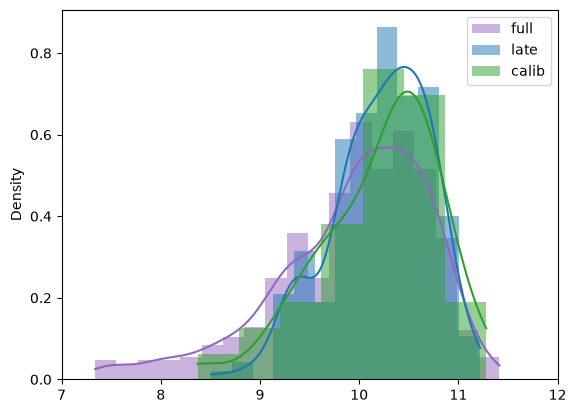

In [2]:
from itertools import chain
from more_itertools import stagger
import seaborn as sns
from seaborn.distributions import _freedman_diaconis_bins

data_full = np.load(f'data/pkg/{DNBASE}.npz')
data_late = np.load(f'data/pkg/{DNBASE}+late.npz')

x = np.linspace(7, 12, 501)

hdata = {}
for key, df, mask, clr in (
    ('full', data_full, data_full['hf_mask'], 'tab:purple'),
    ('late', data_late, data_late['hf_mask'], 'tab:blue'),
    ('calib', data_late, ~data_late['hf_mask'], 'tab:green'),
):
    df = df['logmass'][mask * (df['logmass'] > 7) * (df['logmass'] < 12)]
    b = plt.hist(df, bins=_freedman_diaconis_bins(df), density=True, alpha=0.5, color=clr, label=key)
    k = sns.kdeplot(df, color=clr, cut=0).lines[-1]

    hdata[key] = {
        'range': ':'.join(map(str, b[1][(0, -1),])),
        'hist': points_to_coords(np.transpose((list(chain(*stagger(b[1], (0, 1)))), list(chain(*stagger(b[0], (0, 0))))))),
        'kde': points_to_coords(np.transpose(k.get_data()))
    }
#
plt.gca().set(xlim=(7, 12))
plt.legend();

In [3]:
from scipy.stats import kstest

for d in (data_late, data_full):
    print(kstest(
        data_late['logmass'][(~data_late['hf_mask']) * (data_late['logmass'] > 7) * (data_late['logmass'] < 12)],
        d['logmass'][(d['hf_mask']) * (d['logmass'] > 7) * (d['logmass'] < 12)]
    ))

KstestResult(statistic=np.float64(0.11403508771929824), pvalue=np.float64(0.761961501029997), statistic_location=np.float64(10.415), statistic_sign=np.int8(-1))
KstestResult(statistic=np.float64(0.19872366705551361), pvalue=np.float64(0.09907691566202463), statistic_location=np.float64(10.192), statistic_sign=np.int8(-1))


In [4]:
open('paper/plotdata/masses.tex', 'w').write(str(to_pgfdata(hdata, 'private/masses')))

13853

## Corner

In [5]:
basenames = (
    'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr',
    'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm',
    'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+late',
    'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+highz',
    'pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+late+highz',
)

In [6]:
for name in basenames:
    res = pickle.load(open(f'res/{name}/{VARBASE}.pickle', 'rb')).stack({'sample': ('chain', 'draw')})[['h', 'q0']].to_dataframe()
    h = res['h'].sample(n=1000, weights=norm(-0.5, 0.03).pdf(res['q0']), replace=True)
    print(name, h.mean(), h.std())

pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr 0.75636715 0.010763656347990036
pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm 0.7222894 0.011196117848157883
pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+late 0.7258049 0.010699252597987652
pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+highz 0.7211664 0.011358195915818214
pplus-cdd_nom+ztfdr2-vlhq_nom-pcorr-sm+late+highz 0.7287081 0.011687889695167542


In [7]:
open('paper/plotdata/res-qprior.tex', 'w').write(str(to_pgfdata({
    f'{name}/{VARBASE}/qprior': {'mean': 100*wres.mean().item(), 'std': 100*wres.std().item()}
    for name in basenames for wres in [get_whres(
        pickle.load(open(f'res/{name}/{VARBASE}.pickle', 'rb')).stack({'sample': ('chain', 'draw')})[['h', 'q0']]
    )]
}, 'private')))

1080

In [8]:
from itertools import combinations, repeat

from scipy.stats import chi2
from uplot.contour import kdecontour

GLOBAL_PARAMS = [
    'h', 'q0',
    'M0', 'sigma_res', 'alpha', 'alpha_c', 'beta',
    'mean_x', 'sigma_x', 'mean_c', 'sigma_c',
    'mean_R', 'sigma_R', 'tau',
]

open('paper/plotdata/corner.tex', 'w').write(str(to_pgfdata({
    name: {
        f'{x}-{y}': dict(zip((1, 2), map(points_to_coords, cntrs.values())))
        for x, y in tqdm(combinations(GLOBAL_PARAMS, 2), total=len(GLOBAL_PARAMS)*(len(GLOBAL_PARAMS)-1) // 2)
        for cntrs in [kdecontour(res[x], res[y], chi2(2).cdf([1, 4]))]
    }
    for name in map('/'.join, zip(basenames, repeat(VARBASE)))
    for res in [pickle.load(open(f'res/{name}.pickle', 'rb')).stack({'sample': ('chain', 'draw')})[GLOBAL_PARAMS].to_dataframe()]
}, namespace='private/corner')))

  0%|          | 0/91 [00:00<?, ?it/s]

  0%|          | 0/91 [00:00<?, ?it/s]

  0%|          | 0/91 [00:00<?, ?it/s]

  0%|          | 0/91 [00:00<?, ?it/s]

  0%|          | 0/91 [00:00<?, ?it/s]

7066923

In [9]:
ress = [
    pickle.load(open(f'res/{basename}/{VARBASE}.pickle', 'rb')).stack({'sample': ('chain', 'draw')})
    for basename in basenames
]
LABELS = {
    'M0': r'\Mo', 'sigma_res': r'\sigmares',
    'alpha': r'\saltalpha', 'alpha_c': r'\saltalphac', 'beta': r'\saltbeta',
    'mean_x': r'\meansaltx', 'sigma_x': r'\stdsaltx',
    'mean_c': r'\meansaltc', 'sigma_c': r'\stdsaltc',
    'mean_R': r'\meanRv', 'sigma_R': r'\sigmaRv',
    'tau': r'\bsntau'
}
for param in GLOBAL_PARAMS:
    add_style_line(f'\\defineparam{{{param}}}{{{LABELS.get(param, "")}}}{{}}{{{min(r[param].mean()-2.5*r[param].std() for r in ress):.4f}}}{{{max(r[param].mean()+2.5*r[param].std() for r in ress):.4f}}}')

\defineparam{h}{}{}{0.6789}{0.7730}
\defineparam{q0}{}{}{-2.5138}{1.5114}
\defineparam{M0}{\Mo}{}{-19.3011}{-18.8836}
\defineparam{sigma_res}{\sigmares}{}{0.0661}{0.1222}
\defineparam{alpha}{\saltalpha}{}{-0.1956}{-0.1046}
\defineparam{alpha_c}{\saltalphac}{}{-0.0253}{0.0154}
\defineparam{beta}{\saltbeta}{}{-0.1804}{3.5090}
\defineparam{mean_x}{\meansaltx}{}{-0.4376}{-0.0460}
\defineparam{sigma_x}{\stdsaltx}{}{0.7031}{1.0530}
\defineparam{mean_c}{\meansaltc}{}{-0.1045}{-0.0554}
\defineparam{sigma_c}{\stdsaltc}{}{0.0185}{0.0653}
\defineparam{mean_R}{\meanRv}{}{1.3826}{2.8927}
\defineparam{sigma_R}{\sigmaRv}{}{0.2083}{1.4286}
\defineparam{tau}{\bsntau}{}{0.2519}{0.3927}


In [10]:
from uplot.tikz.commands import Subcommand

for i, y in enumerate(GLOBAL_PARAMS[1:], 1):
    for j, x in enumerate(GLOBAL_PARAMS[:-1]):
        print(Subcommand(r'\nextgroupplot', options=(
            ({'bottom edge': None} if i==len(GLOBAL_PARAMS)-1 else {})
            | ({'left edge': None} if j==0 else {})
        ), additional_options=f'plot={{{x}}}{{{y}}}' if i>j else 'group/empty plot'))
    print()

\nextgroupplot[left edge, plot={h}{q0}]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]

\nextgroupplot[left edge, plot={h}{M0}]
\nextgroupplot[plot={q0}{M0}]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]
\nextgroupplot[group/empty plot]

\nextgroupplot[left edge, plot={h}{sigma_res}]
\nextgroupplot[plot={q0}{sigma_res}]
\nextgroupplot[plot={M0}{sigma_res}]
\nextgro

## Data

In [2]:
data = dict(np.load(f'data/pkg/{DNBASE}.npz'))
data['m'], data['x1'], data['c'] = data['obs'].T

res = pickle.load(open(f'res/{DNBASE}/{VARBASE}.pickle', 'rb')).stack({'sample': ('chain', 'draw')})
res['Om0'] = (2/3)*(1+res['q0'])

/var/folders/3d/6wbmhv2554b45kndmp6nc_bh0000gn/T/ipykernel_98175/1106313756.py:5: FutureWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'sample'} to avoid an error in the future.
  res['Om0'] = (2/3)*(1+res['q0'])


In [3]:
from scipy.stats import norm
from uplot.corner.gaussian_corner import covariance_ellipse

for pname in ('h', 'q0', 'Om0', 'M0', 'sigma_res', 'alpha', 'alpha_c', 'beta', 'mean_x', 'sigma_x', 'mean_c', 'sigma_c', 'mean_R', 'sigma_R', 'tau'):
    p = res[pname]
    m = p.median().item()
    print(f'{pname:>9}: {p.mean():.4f}+-{p.std():.4f} ({m:.4f} +{m-p.quantile(norm().cdf(-1)):.4f} -{p.quantile(norm().cdf(1))-m:.4f})')
    # res['h'].mean().item(), res['h'].std().item(), res['h'].mean().item() - res['h'].quantile(norm().cdf([-1, 1])).to_numpy()

qhslope = 1/np.tan(covariance_ellipse(*np.cov(res['h'], res['Om0'])[(0, 1, 1), (0, 1, 0)])[2])

add_style_line(r'\setdata{qhslope}{'+str(100*qhslope)+'}')

for lbl, m, s in (('Planck', 67.4, 0.5), ('SH0ES', 73, 1), ('DESI', 68.5, 0.6)):
    for suffix, r in (('', res['h']), ('-qprior', get_whres(res))):
        add_style_line(r'\setdata{tension'+suffix+'/'+lbl+'}{'+str(
            abs(m - float(100*r.mean())) / (s**2 + float(100*r.std())**2)**0.5
        )+'}')

        h: 0.7160+-0.0146 (0.7153 +0.0136 -0.0154)
       q0: -0.0779+-0.6168 (-0.0467 +0.6767 -0.6481)
      Om0: 0.6147+-0.4112 (0.6355 +0.4511 -0.4320)
       M0: -19.1301+-0.0556 (-19.1278 +0.0580 -0.0531)
sigma_res: 0.0960+-0.0093 (0.0963 +0.0099 -0.0091)
    alpha: -0.1297+-0.0082 (-0.1295 +0.0082 -0.0080)
  alpha_c: -0.0044+-0.0033 (-0.0044 +0.0033 -0.0032)
     beta: 1.2815+-0.4432 (1.3038 +0.4608 -0.4157)
   mean_x: -0.2987+-0.0351 (-0.2996 +0.0337 -0.0362)
  sigma_x: 0.9858+-0.0250 (0.9852 +0.0247 -0.0254)
   mean_c: -0.0792+-0.0047 (-0.0794 +0.0046 -0.0049)
  sigma_c: 0.0359+-0.0046 (0.0359 +0.0049 -0.0046)
   mean_R: 2.4572+-0.0947 (2.4599 +0.0970 -0.0891)
  sigma_R: 0.6485+-0.0921 (0.6395 +0.0813 -0.0983)
      tau: 0.3400+-0.0150 (0.3399 +0.0152 -0.0151)
\setdata{qhslope}{-2.3482429173797295}
\setdata{tension/Planck}{2.7135348946203277}
\setdata{tension-qprior/Planck}{4.068532251027092}
\setdata{tension/SH0ES}{0.7891651288264089}
\setdata{tension-qprior/SH0ES}{0.482591378

In [13]:
d = {key: val[data['hf_mask']] for key, val in data.items() if len(val) == len(data['hf_mask'])} | {key: data[key] for key in ('z', 'is_late', 'is_highz')} | {
    'z_err': np.diagonal(data['z_cov'])**0.5
}
r = res[{'SN': data['hf_mask']}]

add_style_line(r'\setdata{Ncalib}{'+str((~data['hf_mask']).sum().item())+'}')
add_style_line(r'\setdata{Nhf/base}{'+str(len(d['obs']))+'}')
add_style_line(r'\setdata{Nhf/late}{'+str(d['is_late'].sum().item())+'}')
add_style_line(r'\setdata{Nhf/highz}{'+str(d['is_highz'].sum().item())+'}')
add_style_line(r'\setdata{Nhf/latehz}{'+str((d['is_late']*d['is_highz']).sum().item())+'}')

\setdata{Ncalib}{42}
\setdata{Nhf/base}{772}
\setdata{Nhf/late}{228}
\setdata{Nhf/highz}{705}
\setdata{Nhf/latehz}{205}


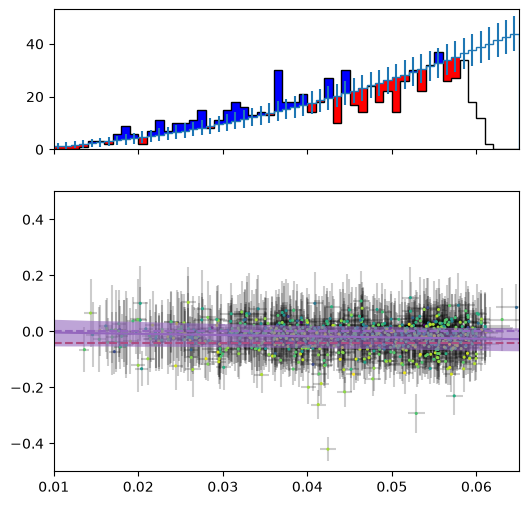

In [14]:
from astropy import units
from astropy.cosmology import FlatLambdaCDM
from libech0ez.model_numpyro import distmod_qj

M0 = r['M0'].mean().item()
h = r['h'].mean().item()
cosmo = FlatLambdaCDM(Om0=0.33, H0=100*h)
gridz = np.linspace(0.01, 0.065, 111)


fig, axs = plt.subplots(2, 1, sharex='col', figsize=(6, 6), height_ratios=(1, 2))

bc, be = np.histogram(d['z'], np.linspace(0.01, 0.065, 56))
bm = (be[1:]+be[:-1])/2

rpred = len(d['z'])*(be[1:]-be[:-1]) * (4*np.pi*units.steradian*cosmo.differential_comoving_volume(bm)/(cosmo.comoving_volume(0.06)-cosmo.comoving_volume(be[0]))).to('').value

axs[0].stairs(np.maximum(bc, rpred)[:-7], be[:-7], baseline=rpred[:-7], fill=True, color='blue')
axs[0].stairs(np.minimum(bc, rpred)[:-7], be[:-7], baseline=rpred[:-7], fill=True, color='red')

axs[0].stairs(bc, be, color='k')
# axs[0].plot(bm, bc, 'k.')

axs[0].errorbar(bm, rpred, rpred**0.5, color='tab:blue', ls='none')
axs[0].stairs(rpred, be, color='tab:blue')

ax = axs[1]
for (x, xerr, y, yerr), clr in (
    # ((d['z'], d['z_err'], d['m'], d['cov'][:, 0, 0]**0.5), 'k'),
    ((
        r['z_hf'].mean('sample'), r['z_hf'].std('sample'),
        (r['M0']+r['distmod']+r['deltaM']).mean('sample'),
        (r['M0']+r['distmod']+r['deltaM']).std('sample')
     ), 'tab:green'),
):
    pred = M0 + cosmo.distmod(x).to('mag').value
    ax.errorbar(x, y-pred, yerr, xerr, color='k', ls='none', alpha=0.2, capsize=0, zorder=1)
    # ax.plot(x, y-pred, '.', color=clr, ms=5, mew=0, alpha=0.3, zorder=1)
    ax.scatter(x, y-pred, s=5, c=data['logmass'][data['hf_mask']], lw=0)

# ax.axhline(0, color='tab:blue')

gridy = r['M0'].to_numpy()[:, None] + jax.vmap(distmod_qj, (0, None, None, None), -1)(gridz, r['h'].to_numpy(), r['q0'].to_numpy(), r['j0'].to_numpy())
gridpred = M0 + cosmo.distmod(gridz).to('mag').value

for _h, clr in ((r['h'].mean('sample'), 'tab:purple'), (0.73, 'tab:red')):
    ax.axhline(-5*np.log10(100*_h/cosmo.H0.to('km/s/Mpc').value), color=clr, ls='--', zorder=2)

clr = 'tab:purple'
ax.fill_between(gridz, *np.quantile(gridy-gridpred, [0.16, 0.84], 0), zorder=2, alpha=0.6, lw=0, color=clr)
ax.plot(gridz, np.mean(gridy-gridpred, 0), zorder=2, color=clr)


ax.set(xlim=gridz[(0, -1),], ylim=(-0.5, 0.5));

#### Write HD

In [22]:
add_style_line(r'\newcommand{\fidh}{'+str(h)+'}')
add_style_line(r'\newcommand{\fidOmo}{'+str(cosmo.Om0)+'}')

\newcommand{\fidh}{0.7160026431083679}
\newcommand{\fidOmo}{0.33}


In [16]:
from libech0ez import ztf_offz, ztf_off, ztf_offerr

pd.DataFrame({'z': ztf_offz, 'off': ztf_off, 'err': ztf_offerr}).to_csv('paper/plotdata/ztf-offset.txt', **csvkwargs)

In [17]:
open('paper/plotdata/hd.tex', 'w').write(str(to_pgfdata({
    f'{key}/{lbl}': val
    for lbl, H0, M in (
        ('us', 100*r['h'].mean('sample').item(), (r['M0'] - 5*np.log10(r['h'])).mean('sample')),
        ('Planck', 67.4, M0 - 5*np.log10(0.674)),
        ('SH0ES', 73, M0 - 5*np.log10(0.73))
    ) for key, val in (('H0', H0), ('dM', (M - (M0 - 5*np.log10(cosmo.H0.to('km/s/Mpc').value/100))).item()))
} | {
    key: r[key].mean('sample').item() for key in ('h', 'mean_c', 'sigma_c')
}, 'private/hd')))

354

In [18]:
df = pd.DataFrame({
    'z_obs': d['z'], 'z_err': d['z_err'],
    'm_obs': d['m'], 'm_err': d['cov'][:, 0, 0]**0.5,
    'c_obs': d['c'], 'x_obs': d['x1'],
    'z_mean': r['z_hf'].mean('sample'), 'z_std': r['z_hf'].std('sample'),
    'm_mean': (r['M0']+r['distmod']+r['deltaM']).mean('sample'),
    'm_std': (r['M0']+r['distmod']+r['deltaM']).std('sample'),
    'logmass': d['logmass'],
    'is_late': d['is_late'].astype(int)
})
df['pred_obs'] = M0 + cosmo.distmod(df['z_obs']).to('mag').value
df['pred'] = M0 + cosmo.distmod(df['z_mean']).to('mag').value
df.to_csv('paper/plotdata/hd.txt', **csvkwargs)

In [19]:
pd.DataFrame({
    'z': gridz, 'pred': gridpred,
    'y_mean': np.mean(gridy, axis=0)
} | dict(zip(('y_low', 'y_high'), np.quantile(gridy, (0.16, 0.84), axis=0)))).set_index('z').assign(
    ratepred=pd.Series(rpred, index=bm),
    ratepred_std=pd.Series(rpred**0.5, index=bm)
).reset_index().to_csv('paper/plotdata/hd_grid.txt', **csvkwargs)

In [20]:
pd.DataFrame({'be': be}).assign(**{key: pd.Series(val) for key, val in {
    'bm': bm, 'bc': bc, 'rpred': rpred
}.items()}).to_csv('paper/plotdata/hd_bins.txt', **{**csvkwargs, 'na_rep': '0'})

## Write style

In [21]:
open('paper/plotdata/res-style.tex', 'w').write('\n'.join(STYLE_LINES))

1065